# Day 1: Representation as Measurement

The goal today is to see how text becomes data. The same corpus can support different conclusions depending on the unit of analysis, preprocessing, feature weighting, and similarity measure.

By the end you should be able to:

1. Explain what spaCy contributes to an NLP workflow.
2. Build a document-term matrix.
3. Compare raw counts, binary counts, normalized counts, and TF-IDF.
4. Explain what common preprocessing choices remove or preserve.
5. Compute document similarity.
6. Compare groups using distinctive words.

In [4]:
# Import tools for tables, visualizations, text features, and vector comparisons.
import re
from pathlib import Path

# NumPy handles arrays and matrix totals; pandas holds labeled tables.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# scikit-learn supplies text-to-matrix tools, dimensionality reduction, and similarity.
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Show longer text snippets in tables without truncating them too early.
pd.set_option('display.max_colwidth', 120)


In [5]:
# Find the local data folder whether Jupyter starts in the repository or notebook directory.
from pathlib import Path


# Jupyter may start in the repository root or in materials/notebooks.
def find_data_dir():
    # Try the likely relative paths in order; Path joins folders across operating systems.
    candidates = [Path('../data'), Path('materials/data'), Path('data')]
    for candidate in candidates:
        # Use the first folder that is present on this computer.
        if candidate.exists():
            return candidate
    raise FileNotFoundError('Could not find the course data directory.')


# Keep the chosen folder in one variable for all later data loads.
DATA_DIR = find_data_dir()
DATA_DIR


PosixPath('../data')

## spaCy setup

The notebooks use spaCy for tokenization and preprocessing. If `en_core_web_sm` is installed, the same setup also shows POS tags, lemmas, and dependency parses. If not, the notebooks still run with a blank English tokenizer.

In [6]:
# Load a spaCy pipeline and define the token rules used throughout this notebook.
import spacy

# The trained model adds tags, lemmas, parsing, and named entities.
try:
    nlp = spacy.load('en_core_web_sm')
    print('Loaded spaCy model: en_core_web_sm')
except OSError:
    # Fallback: a blank English pipeline still tokenizes text, but has no trained annotations.
    nlp = spacy.blank('en')
    nlp.add_pipe('sentencizer')
    print('Using spacy.blank("en"). Install en_core_web_sm for POS tags, lemmas, dependency parses, and named entities.')


# These switches decide which tokens will be eligible as word features.
# Inputs: raw text and three switches for stop words, nonletters, and short tokens.
# Output: a list of lowercased word features used by the vectorizers below.
def spacy_preprocess(text, remove_stop=True, keep_alpha=True, min_len=2):
    """Tokenize and lightly preprocess text with spaCy."""
    # make_doc tokenizes only; it does not run the model's slower tagging/parsing steps.
    doc = nlp.make_doc(str(text))
    tokens = []
    for token in doc:
        # Skip numbers and punctuation when keep_alpha=True.
        if keep_alpha and not token.is_alpha:
            continue
        # Skip spaCy's common-word list when remove_stop=True.
        if remove_stop and token.is_stop:
            continue
        # Lowercasing makes 'Policy' and 'policy' the same feature.
        term = token.text.lower()
        if len(term) >= min_len:
            tokens.append(term)
    return tokens


# CountVectorizer calls this function once per document to obtain its features.
def spacy_analyzer(text):
    return spacy_preprocess(text)


# This alternate analyzer returns both the usual unigrams and two-word features.
def spacy_analyzer_with_bigrams(text):
    """Keep the usual unigrams and add adjacent word pairs."""
    unigrams = spacy_preprocess(text)
    # Keep the original token order so a bigram really was adjacent in the text.
    original_tokens = list(nlp.make_doc(str(text)))
    # Make pairs before stop-word removal: otherwise distant words can
    # become false neighbors and phrases such as 'not good' disappear.
    # zip(tokens, tokens[1:]) walks over neighboring pairs; an underscore joins each pair into one feature.
    bigrams = [
        left.text.lower() + '_' + right.text.lower()
        for left, right in zip(original_tokens, original_tokens[1:])
        if left.is_alpha and right.is_alpha
        and len(left.text) >= 2 and len(right.text) >= 2
    ]
    # The same document can contribute single words and word pairs to one matrix.
    return unigrams + bigrams


# Return one row per token to reveal what spaCy recognized and what preprocessing keeps.
def spacy_token_table(text):
    """Show tokenization, preprocessing flags, and parses when a full model is available."""
    # Unlike make_doc, calling nlp runs available model components for tags and entities.
    doc = nlp(str(text))
    rows = []
    for token in doc:
        rows.append({
            'text': token.text,
            'lemma': token.lemma_ or '(model needed)',
            'pos': token.pos_ or '(model needed)',
            'dep': token.dep_ or '(model needed)',
            'head': token.head.text if token.dep_ else '(model needed)',
            'ent_type': token.ent_type_ or '',
            'is_alpha': token.is_alpha,
            'is_stop': token.is_stop,
            'like_num': token.like_num,
            # Apply our default word rules to this token so the last column explains feature selection.
            'kept_by_preprocess': token.text.lower() in spacy_preprocess(token.text, remove_stop=True)
        })
    return pd.DataFrame(rows)


Loaded spaCy model: en_core_web_sm


## 1. What spaCy does

spaCy is a practical NLP library for turning raw text into linguistic objects. In this course we mainly use it for preprocessing before statistical modeling, but the same pipeline can also support sentence segmentation, part-of-speech tagging, lemmatization, dependency parsing, named-entity recognition, rule-based matching, and feature extraction.

The important distinction is that spaCy gives us linguistic annotations; it does not, by itself, decide which representation is valid for a research question. We still choose what to count, remove, preserve, and validate.

In [7]:
# List the components available in this spaCy pipeline and what each can add.
# Map pipeline component names to a plain-language description for the first table.
component_descriptions = {
    'tok2vec': 'contextual token features used by later components',
    'tagger': 'part-of-speech tags such as NOUN, VERB, ADJ',
    'parser': 'dependency parse and sentence boundaries',
    'attribute_ruler': 'rule-based token attributes and exceptions',
    'lemmatizer': 'dictionary/base forms such as studies -> study',
    'ner': 'named entities such as people, places, organizations',
    'sentencizer': 'rule-based sentence boundaries'
}

# The tokenizer is always present; nlp.pipe_names lists optional installed components.
pipeline_table = pd.DataFrame({
    'component': ['tokenizer'] + list(nlp.pipe_names),
    'what_it_adds': ['splits text into tokens'] + [component_descriptions.get(name, 'pipeline component') for name in nlp.pipe_names]
})

# Check components rather than assuming the trained model is installed.
capabilities = pd.DataFrame([
    {'capability': 'tokenization', 'available': True, 'typical_use': 'define words, punctuation, URLs, numbers'},
    {'capability': 'sentence segmentation', 'available': any(name in nlp.pipe_names for name in ['parser', 'senter', 'sentencizer']), 'typical_use': 'split speeches/articles into sentences'},
    {'capability': 'lemmatization', 'available': 'lemmatizer' in nlp.pipe_names, 'typical_use': 'collapse inflected forms'},
    {'capability': 'part-of-speech tags', 'available': 'tagger' in nlp.pipe_names, 'typical_use': 'keep nouns/verbs/adjectives or study style'},
    {'capability': 'dependency parsing', 'available': 'parser' in nlp.pipe_names, 'typical_use': 'inspect grammatical relations'},
    {'capability': 'named entities', 'available': 'ner' in nlp.pipe_names, 'typical_use': 'extract people, organizations, places, dates'}
])

# display renders a readable table in Jupyter instead of printing its Python representation.
display(pipeline_table)
display(capabilities)


,component,what_it_adds
0,tokenizer,splits text into tokens
1,tok2vec,contextual token features used by later components
2,tagger,"part-of-speech tags such as NOUN, VERB, ADJ"
3,parser,dependency parse and sentence boundaries
4,attribute_ruler,rule-based token attributes and exceptions
5,lemmatizer,dictionary/base forms such as studies -> study
6,ner,"named entities such as people, places, organizations"


,capability,available,typical_use
0,tokenization,True,"define words, punctuation, URLs, numbers"
1,sentence segmentation,True,split speeches/articles into sentences
2,lemmatization,True,collapse inflected forms
3,part-of-speech tags,True,keep nouns/verbs/adjectives or study style
4,dependency parsing,True,inspect grammatical relations
5,named entities,True,"extract people, organizations, places, dates"


### A sentence as a spaCy document

A spaCy `Doc` contains tokens plus optional annotations. The table below shows how one sentence is represented. If the full English model is installed, you will see lemmas, POS tags, dependency labels, syntactic heads, and named-entity types. With the blank fallback model, only tokenizer-level attributes are available.

In [7]:
# Process one sentence so we can inspect tokens and linguistic annotations.
spacy_example = 'The European Commission proposed new regulations on bananas and chocolate!'
# Run the complete available spaCy pipeline on this one sentence.
example_doc = nlp(spacy_example)

# Inspect one row per token, including whether our later analyzer would keep it.
spacy_token_table(spacy_example)


,text,lemma,pos,dep,head,ent_type,is_alpha,is_stop,like_num,kept_by_preprocess
0,The,the,DET,det,Commission,ORG,True,True,False,False
1,European,European,PROPN,compound,Commission,ORG,True,False,False,True
2,Commission,Commission,PROPN,nsubj,proposed,ORG,True,False,False,True
3,proposed,propose,VERB,ROOT,proposed,,True,False,False,True
4,new,new,ADJ,amod,regulations,,True,False,False,True
5,regulations,regulation,NOUN,dobj,proposed,,True,False,False,True
6,on,on,ADP,prep,regulations,,True,True,False,False
7,bananas,banana,NOUN,pobj,on,,True,False,False,True
8,and,and,CCONJ,cc,bananas,,True,True,False,False
9,chocolate,chocolate,NOUN,conj,bananas,,True,False,False,True


In [8]:
# Collect any named entities found in the example sentence.
# An entity has text, a type label, and start/end positions in the token sequence.
entity_rows = [
    {
        'entity': ent.text,
        'label': ent.label_,
        'start_token': ent.start,
        'end_token': ent.end
    }
    # This list is empty when the blank fallback has no NER component.
    for ent in example_doc.ents
]

if entity_rows:
    display(pd.DataFrame(entity_rows))
else:
    print('No named entities available. Install en_core_web_sm to run the NER component.')


,entity,label,start_token,end_token
0,The European Commission,ORG,0,3


### Visualizing parses and entities

For teaching and error analysis, visual inspection is useful. spaCy's `displaCy` can render dependency parses and named entities directly inside a notebook. These views are diagnostics: they help us decide whether the preprocessing pipeline is appropriate for the texts we are studying.

In [9]:
# Display the dependency and entity views only when the loaded model supports them.
from IPython.display import HTML
from spacy import displacy

# Dependency arrows need a trained parser; do not render them with the blank pipeline.
if 'parser' in nlp.pipe_names:
    dep_html = displacy.render(example_doc, style='dep', page=False, jupyter=False, options={'compact': True, 'distance': 90})
    display(HTML(dep_html))
else:
    print('Dependency visualization skipped because the parser is not available.')

# Highlighted entity spans need both an NER component and detected entities.
if 'ner' in nlp.pipe_names and list(example_doc.ents):
    ent_html = displacy.render(example_doc, style='ent', page=False, jupyter=False)
    display(HTML(ent_html))
else:
    print('Entity visualization skipped because NER is not available or no entities were found.')


### Batch processing with `nlp.pipe`

For a few sentences, calling `nlp(text)` is fine. For hundreds or thousands of documents, `nlp.pipe()` is the standard spaCy pattern. It streams texts through the pipeline efficiently and returns one `Doc` per text.

,doc_id,n_tokens,n_alpha_tokens,n_sentences,entities
0,1,13,11,1,(none)
1,2,10,9,1,Vienna (GPE)
2,3,9,8,1,(none)
3,4,12,9,1,(none)


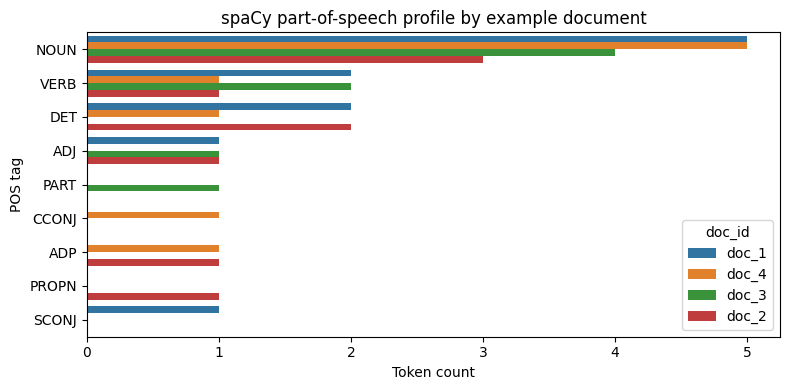

In [10]:
# Process several documents as a batch and compare their token and POS profiles.
spacy_demo_texts = [
    'Courts blocked the policy after civil-rights groups filed a lawsuit.',
    'The minister announced a new climate package in Vienna.',
    'Researchers used transformer models to classify parliamentary speeches.',
    'Voters discussed inflation, housing, and migration during the campaign.'
]

# nlp.pipe processes a batch efficiently while preserving the text order.
demo_docs = list(nlp.pipe(spacy_demo_texts))
summary_rows = []
pos_rows = []
# Build one document summary and a second, token-level table for POS counts.
for doc_id, doc in enumerate(demo_docs, start=1):
    entities = ', '.join(f'{ent.text} ({ent.label_})' for ent in doc.ents) or '(none)'
    summary_rows.append({
        'doc_id': doc_id,
        'n_tokens': len(doc),
        # Count only alphabetic tokens, excluding punctuation and numbers.
        'n_alpha_tokens': sum(token.is_alpha for token in doc),
        # doc.sents is an iterator, so sum counts its sentence spans.
        'n_sentences': sum(1 for _ in doc.sents),
        'entities': entities
    })
    for token in doc:
        if token.is_alpha:
            pos_rows.append({'doc_id': f'doc_{doc_id}', 'pos': token.pos_ or 'unknown'})

batch_summary = pd.DataFrame(summary_rows)
# Group by document and POS label; 'unknown' is expected without a trained tagger.
pos_counts = pd.DataFrame(pos_rows).value_counts(['doc_id', 'pos']).reset_index(name='tokens')

display(batch_summary)

plt.figure(figsize=(8, 4))
# Compare tag counts across the four example documents.
sns.barplot(data=pos_counts, x='tokens', y='pos', hue='doc_id')
plt.title('spaCy part-of-speech profile by example document')
plt.xlabel('Token count')
plt.ylabel('POS tag')
plt.tight_layout()


### Practical uses in text analysis projects

Common spaCy uses in applied text analysis:

1. Preprocessing: tokenize, lowercase, remove stop words, keep only alphabetic tokens, or lemmatize.
2. Feature engineering: count nouns, verbs, entities, sentence lengths, dependency labels, or custom patterns.
3. Quality control: inspect whether tokenization and sentence segmentation work for a corpus.
4. Information extraction: identify organizations, people, dates, locations, and domain-specific phrase patterns.
5. Scaling up: process many documents with `nlp.pipe()` before statistical modeling.

The rest of this notebook uses spaCy primarily as a transparent preprocessing layer before building document-term matrices.

## 2. A tiny corpus

Start with a toy example where every transformation is visible. This is not realistic, but it makes the representation choices inspectable.

In [11]:
# Create a tiny labeled corpus so every feature can be inspected by hand.
toy_texts = [
    'John loves ice cream and oranges.',
    'Mary loves chocolate ice cream.',
    'John dislikes chocolate but loves oranges.',
    'Mary hates oranges and loves chocolate. But she loves bananas more.'
]

# Each row is one document; speaker is metadata, not a word feature.
toy = pd.DataFrame({
    'doc_id': ['doc_1', 'doc_2', 'doc_3', 'doc_4'],
    'speaker': ['John', 'Mary', 'John', 'Mary'],
    'text': toy_texts
})
toy


,doc_id,speaker,text
0,doc_1,John,John loves ice cream and oranges.
1,doc_2,Mary,Mary loves chocolate ice cream.
2,doc_3,John,John dislikes chocolate but loves oranges.
3,doc_4,Mary,Mary hates oranges and loves chocolate. But she loves bananas more.


## 3. From spaCy tokens to features

This table shows what spaCy sees in one toy sentence. With `en_core_web_sm`, the lemma, POS, dependency, syntactic head, and entity columns become real annotations; with the fallback tokenizer, tokenization and lexical flags still work.

The key modeling choice comes next: once spaCy has produced tokens, we decide which token attributes become columns in a document-term matrix.

In [12]:
# Show how spaCy tokenizes the first toy document.
spacy_token_table(toy_texts[0])


,text,lemma,pos,dep,head,ent_type,is_alpha,is_stop,like_num,kept_by_preprocess
0,John,John,PROPN,nsubj,loves,PERSON,True,False,False,True
1,loves,love,VERB,ROOT,loves,,True,False,False,True
2,ice,ice,NOUN,compound,cream,,True,False,False,True
3,cream,cream,NOUN,dobj,loves,,True,False,False,True
4,and,and,CCONJ,cc,cream,,True,True,False,False
5,oranges,orange,NOUN,conj,cream,,True,False,False,True
6,.,.,PUNCT,punct,loves,,False,False,False,False


,doc_id,n_tokens,n_alpha_tokens,n_sentences,entities
0,1,7,6,1,John (PERSON)
1,2,6,5,1,Mary (PERSON)
2,3,7,6,1,John (PERSON)
3,4,7,6,1,Mary (PERSON)


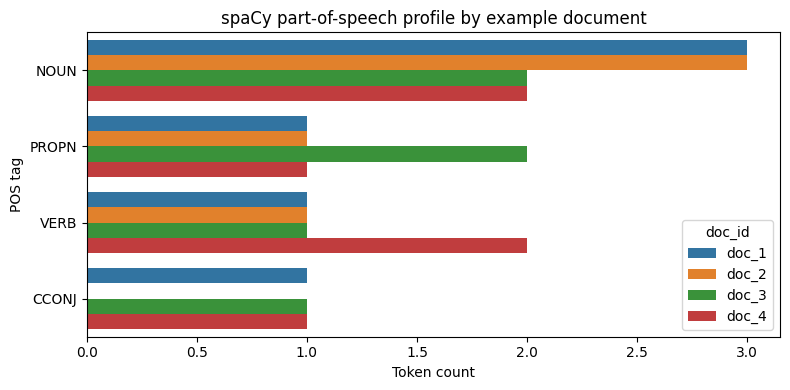

In [ ]:
# nlp.pipe processes a batch efficiently while preserving the text order.
demo_docs = list(nlp.pipe(toy_texts))
summary_rows = []
pos_rows = []
# Build one document summary and a second, token-level table for POS counts.
for doc_id, doc in enumerate(demo_docs, start=1):
    entities = ', '.join(f'{ent.text} ({ent.label_})' for ent in doc.ents) or '(none)'
    summary_rows.append({
        'doc_id': doc_id,
        'n_tokens': len(doc),
        # Count only alphabetic tokens, excluding punctuation and numbers.
        'n_alpha_tokens': sum(token.is_alpha for token in doc),
        # doc.sents is an iterator, so sum counts its sentence spans.
        'n_sentences': sum(1 for _ in doc.sents),
        'entities': entities
    })
    for token in doc:
        if token.is_alpha:
            pos_rows.append({'doc_id': f'doc_{doc_id}', 'pos': token.pos_ or 'unknown'})

batch_summary = pd.DataFrame(summary_rows)
# Group by document and POS label; 'unknown' is expected without a trained tagger.
pos_counts = pd.DataFrame(pos_rows).value_counts(['doc_id', 'pos']).reset_index(name='tokens')

display(batch_summary)

plt.figure(figsize=(8, 4))
# Compare tag counts across the four example documents.
sns.barplot(data=pos_counts, x='tokens', y='pos', hue='doc_id')
plt.title('spaCy part-of-speech profile by example document')
plt.xlabel('Token count')
plt.ylabel('POS tag')
plt.tight_layout()


In [13]:
# Fit a vocabulary on the toy corpus and turn each document into a row of counts.
# Our analyzer supplies the words, so CountVectorizer uses those rules rather than its default tokenizer.
vectorizer = CountVectorizer(analyzer=spacy_analyzer)
# fit learns the vocabulary; transform makes a sparse documents-by-terms count matrix.
X = vectorizer.fit_transform(toy['text'])
 
# Dense conversion is fine for four toy texts; keep large real-corpus matrices sparse.
dtm = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=toy['doc_id'])
dtm


,bananas,chocolate,cream,dislikes,hates,ice,john,loves,mary,oranges
doc_id,,,,,,,,,,
doc_1,0,0,1,0,0,1,1,1,0,1
doc_2,0,1,1,0,0,1,0,1,1,0
doc_3,0,1,0,1,0,0,1,1,0,1
doc_4,1,1,0,0,1,0,0,2,1,1


## 4. Representation choices

Compare several common representations. Ask what each one makes easy to see and what each one hides.

### Methodology formulas: representation as measurement

Most of the notebook turns raw text into a document-feature matrix. If document $d$ contains vocabulary item $v$, the count representation is

$$X_{dv} = c(v, d).$$

TF-IDF keeps local frequency but downweights terms that appear in many documents:

$$\mathrm{tfidf}_{dv} = \mathrm{tf}_{dv} \times \log\left(\frac{N}{\mathrm{df}_v}\right),$$

where $N$ is the number of documents and $\mathrm{df}_v$ is the number of documents containing term $v$. Similarity between two documents is usually measured by cosine similarity:

$$\cos(x_i, x_j) = \frac{x_i^\top x_j}{\lVert x_i \rVert_2\lVert x_j \rVert_2}.$$

For distinctive terms by group, the notebook uses a smoothed log-odds ratio. If $c_{v,A}$ is the count of term $v$ in group $A$, $N_A$ is the total number of term tokens in group $A$, and $\alpha$ is a small smoothing value, then

$$\mathrm{odds}_{v,A}=\frac{c_{v,A}+\alpha}{N_A-c_{v,A}+\alpha}, \qquad \delta_v=\log(\mathrm{odds}_{v,A})-\log(\mathrm{odds}_{v,B}).$$

A rough standard error for the contrast is

$$\mathrm{se}(\delta_v) \approx \sqrt{\frac{1}{c_{v,A}+\alpha}+\frac{1}{c_{v,B}+\alpha}}, \qquad z_v=\frac{\delta_v}{\mathrm{se}(\delta_v)}.$$

This lets us distinguish large but noisy rare-word contrasts from frequent, stable contrasts. The two-dimensional document map later in the notebook uses a low-rank approximation of the feature matrix:

$$X \approx U_k \Sigma_k V_k^\top.$$

In [14]:
# Fit several feature representations to the same toy texts for a direct comparison.
# Every option uses the same four texts; only token rules or weighting change.
representations = {
    'spaCy tokens, raw counts': CountVectorizer(
        analyzer=lambda text: spacy_preprocess(text, remove_stop=False, keep_alpha=True, min_len=1)
    ),
    # binary=True turns any positive within-document count into 1.
    'spaCy tokens, binary word presence': CountVectorizer(
        analyzer=lambda text: spacy_preprocess(text, remove_stop=False, keep_alpha=True, min_len=1),
        binary=True
    ),
    'spaCy preprocessing: no stop words': CountVectorizer(analyzer=spacy_analyzer),
    # TF-IDF downweights words found in many documents relative to more distinctive words.
    'spaCy preprocessing + TF-IDF': TfidfVectorizer(analyzer=spacy_analyzer)
}

# Fit each representation independently, then display its document-term table.
for name, vec in representations.items():
    # Each option learns its own vocabulary, so compare column names as well as values.
    matrix = vec.fit_transform(toy['text'])
    table = pd.DataFrame(matrix.toarray(), columns=vec.get_feature_names_out(), index=toy['doc_id'])
    print()
    print(name.upper())
    display(table.round(3))



SPACY TOKENS, RAW COUNTS


,and,bananas,but,chocolate,cream,dislikes,hates,ice,john,loves,mary,more,oranges,she
doc_id,,,,,,,,,,,,,,
doc_1,1,0,0,0,1,0,0,1,1,1,0,0,1,0
doc_2,0,0,0,1,1,0,0,1,0,1,1,0,0,0
doc_3,0,0,1,1,0,1,0,0,1,1,0,0,1,0
doc_4,1,1,1,1,0,0,1,0,0,2,1,1,1,1



SPACY TOKENS, BINARY WORD PRESENCE


,and,bananas,but,chocolate,cream,dislikes,hates,ice,john,loves,mary,more,oranges,she
doc_id,,,,,,,,,,,,,,
doc_1,1,0,0,0,1,0,0,1,1,1,0,0,1,0
doc_2,0,0,0,1,1,0,0,1,0,1,1,0,0,0
doc_3,0,0,1,1,0,1,0,0,1,1,0,0,1,0
doc_4,1,1,1,1,0,0,1,0,0,1,1,1,1,1



SPACY PREPROCESSING: NO STOP WORDS


,bananas,chocolate,cream,dislikes,hates,ice,john,loves,mary,oranges
doc_id,,,,,,,,,,
doc_1,0,0,1,0,0,1,1,1,0,1
doc_2,0,1,1,0,0,1,0,1,1,0
doc_3,0,1,0,1,0,0,1,1,0,1
doc_4,1,1,0,0,1,0,0,2,1,1



SPACY PREPROCESSING + TF-IDF


,bananas,chocolate,cream,dislikes,hates,ice,john,loves,mary,oranges
doc_id,,,,,,,,,,
doc_1,0.00,0.000,0.494,0.000,0.00,0.494,0.494,0.327,0.000,0.400
doc_2,0.00,0.400,0.494,0.000,0.00,0.494,0.000,0.327,0.494,0.000
doc_3,0.00,0.388,0.000,0.608,0.00,0.000,0.479,0.317,0.000,0.388
doc_4,0.47,0.300,0.000,0.000,0.47,0.000,0.000,0.491,0.371,0.300


## 5. Move to real data

We will use State of the Union speeches. The file has one row per speech, with president, year, party, and text.

In [8]:
# Load the State of the Union corpus and convert its year field to a number.
# Load the supplied State of the Union file; one row represents one speech.
sotu = pd.read_csv(DATA_DIR / 'sotu.csv')
# Invalid or missing years become NaN, which we remove before filtering by year.
sotu['year_numeric'] = pd.to_numeric(sotu['year'], errors='coerce')

sotu[['president', 'year', 'party', 'sotu_type', 'text']].head()


,president,year,party,sotu_type,text
0,George Washington,1790,Nonpartisan,speech,Fellow-Citizens of the Senate and House of Representatives: \n\nI embrace with great satisfaction the opportunity wh...
1,George Washington,1790,Nonpartisan,speech,\n\n Fellow-Citizens of the Senate and House of Representatives: \n\nIn meeting you again I feel much satisfaction i...
2,George Washington,1791,Nonpartisan,speech,"\n\n Fellow-Citizens of the Senate and House of Representatives: \n\n ""In vain may we expect peace with the Indians ..."
3,George Washington,1792,Nonpartisan,speech,Fellow-Citizens of the Senate and House of Representatives: \n\nIt is some abatement of the satisfaction with which ...
4,George Washington,1793,Nonpartisan,speech,\n\n Fellow-Citizens of the Senate and House of Representatives: \n\nSince the commencement of the term for which I ...


In [11]:
# Keep modern speeches from the two parties used in the group comparison.
modern = (
    sotu
    # Remove rows that lack the fields needed for the year, party, or text comparisons.
    .dropna(subset=['year_numeric', 'party', 'text'])
    # Hold the analysis to modern speeches from the two parties used below.
    .query("party in ['Democratic', 'Republican'] and year_numeric >= 1950")
    # Work on an independent DataFrame so adding columns does not modify sotu.
    .copy()
)

# Make short labels for plots and speech-pair tables.
modern['doc_label'] = modern['president'] + ' (' + modern['year'].astype(str) + ')'
modern[['doc_label', 'party', 'sotu_type']].head(), modern.shape


(                       doc_label       party sotu_type
 161        Harry S Truman (1950)  Democratic    speech
 162        Harry S Truman (1951)  Democratic    speech
 163        Harry S Truman (1952)  Democratic    speech
 164  Dwight D. Eisenhower (1953)  Republican   written
 165        Harry S Truman (1953)  Democratic   written,
 (79, 9))

## 6. Most frequent terms

Frequency is simple and useful, but frequent words are not always the
most substantively interesting words.

The vectorizer below uses **min_df=2**. Document frequency counts the
number of speeches containing a term at least once. A term used many
times in only one speech still has document frequency 1, so it is
removed. The **max_features=2000** setting then caps the vocabulary at
the 2,000 most frequent remaining terms.


In [12]:
# Build word counts; min_df=2 keeps terms seen in at least two speeches.
# min_df=2 means a term must appear in at least two *speeches*; max_features keeps the 2,000 most frequent surviving terms.
count_vec = CountVectorizer(analyzer=spacy_analyzer, min_df=2, max_features=2000)
# Rows are speeches; columns are retained terms; values are within-speech counts.
counts = count_vec.fit_transform(modern['text'])
terms = count_vec.get_feature_names_out()

# Sum down the speech rows to get each term's corpus total; ravel makes a 1D array.
term_counts = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=terms)
term_counts.sort_values(ascending=False).head(20).to_frame('count')


,count
new,1997
year,1841
people,1755
world,1710
congress,1688
america,1597
years,1405
government,1335
american,1299
federal,1157


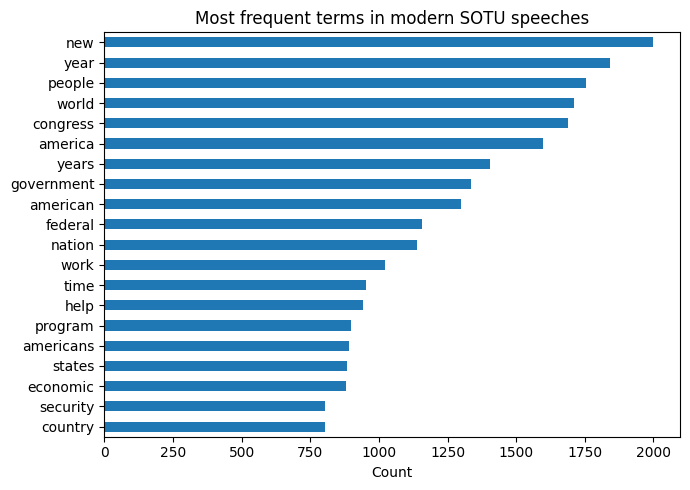

In [13]:
# Plot the most frequent terms after sorting them into readable bar order.
# Select the top 20, then reverse their order so the largest bar appears at the top.
term_counts.sort_values(ascending=False).head(20).sort_values().plot(kind='barh', figsize=(7, 5))
plt.title('Most frequent terms in modern SOTU speeches')
plt.xlabel('Count')
plt.tight_layout()


### Additional demo: sparsity and vocabulary growth

Document-term matrices are mostly zeros. This demo makes that sparsity visible and shows how the observed vocabulary grows as we add speeches in chronological order.

Document-term matrix shape: 79 documents x 2000 terms
Nonzero entries: 65,397 of 158,000
Sparsity: 58.6%


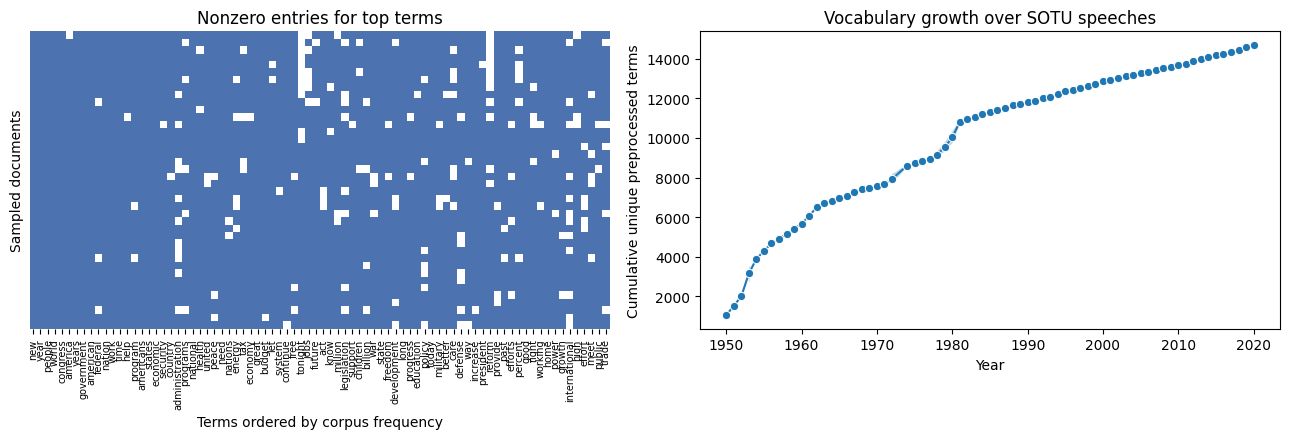

In [14]:
# Measure matrix sparsity and show how the vocabulary grows over time.
# The full matrix has documents times terms possible cells.
matrix_cells = counts.shape[0] * counts.shape[1]
# nnz counts nonzero cells; sparsity is the fraction that remain zero.
sparsity = 1 - counts.nnz / matrix_cells

print(f'Document-term matrix shape: {counts.shape[0]} documents x {counts.shape[1]} terms')
print(f'Nonzero entries: {counts.nnz:,} of {matrix_cells:,}')
print(f'Sparsity: {sparsity:.1%}')

# Show only a sample of rows and common terms so the heatmap stays legible.
sample_rows = np.linspace(0, counts.shape[0] - 1, min(40, counts.shape[0]), dtype=int)
sample_cols = np.asarray(counts.sum(axis=0)).ravel().argsort()[::-1][:80]
# Turn counts into a 0/1 presence picture; this is only for plotting.
sparsity_view = (counts[sample_rows][:, sample_cols] > 0).toarray()
visible_terms = terms[sample_cols]

# A set stores each vocabulary item once as speeches are added in year order.
seen_terms = set()
growth_rows = []
for order, (_, row) in enumerate(modern.sort_values('year_numeric').iterrows(), start=1):
    # update adds any new words in this speech; old words do not increase set size.
    seen_terms.update(spacy_preprocess(row['text']))
    growth_rows.append({
        'speech_number': order,
        'year': row['year_numeric'],
        'vocabulary_size': len(seen_terms)
    })

vocab_growth = pd.DataFrame(growth_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(
    sparsity_view,
    cmap=['white', '#4C72B0'],
    cbar=False,
    xticklabels=visible_terms,
    yticklabels=False,
    ax=axes[0]
)
axes[0].set_title('Nonzero entries for top terms')
axes[0].set_xlabel('Terms ordered by corpus frequency')
axes[0].set_ylabel('Sampled documents')
axes[0].tick_params(axis='x', labelrotation=90, labelsize=7)

# Cumulative vocabulary usually grows as we observe more speeches.
sns.lineplot(data=vocab_growth, x='year', y='vocabulary_size', marker='o', ax=axes[1])
axes[1].set_title('Vocabulary growth over SOTU speeches')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Cumulative unique preprocessed terms')

plt.tight_layout()


## 7. Distinctive terms by group

Here we compare Democratic and Republican speeches using a smoothed log-odds ratio. Positive values are more Democratic in this coding; negative values are more Republican.

The standard error and z-score are not a substitute for substantive validation, but they help avoid over-interpreting rare words that appear only a few times.

In [16]:
# Aggregate counts by party, then use smoothing to keep zero-count log odds finite.
# Convert the limited 2,000-term matrix to a labeled table to aggregate by party.
count_table = pd.DataFrame(counts.toarray(), columns=terms)
# Use row order, not pandas index alignment, to attach each speech's party correctly.
count_table['_party_label'] = modern['party'].to_numpy()

# Sum word counts within each party before converting them to rates.
# Sum token counts across all speeches within each party.
group_counts = count_table.groupby('_party_label')[list(terms)].sum()
group_counts = group_counts.loc[['Democratic', 'Republican']]

dem_counts = group_counts.loc['Democratic']
rep_counts = group_counts.loc['Republican']
# Denominator: all retained word occurrences in Democratic speeches.
dem_total = dem_counts.sum()
# Use the analogous denominator for Republican speeches; groups can differ in size.
rep_total = rep_counts.sum()

# Jeffreys-style smoothing keeps zero counts finite without overwhelming the data.
alpha = 0.5

# For each term, odds = its smoothed count / all other retained terms' smoothed count.
dem_odds = (dem_counts + alpha) / (dem_total - dem_counts + alpha)
rep_odds = (rep_counts + alpha) / (rep_total - rep_counts + alpha)
# Positive values favor Democratic speeches; negative values favor Republican speeches.
log_odds = np.log(dem_odds) - np.log(rep_odds)
# Large uncertainty reduces confidence in extreme rare-word contrasts.
# Approximate standard error is larger when either party uses a term rarely.
log_odds_se = np.sqrt(1 / (dem_counts + alpha) + 1 / (rep_counts + alpha))
# Scale the contrast by uncertainty; a large raw contrast can still be weak evidence.
log_odds_z = log_odds / log_odds_se

# Collect counts, effect size, and uncertainty so we can inspect them together.
distinctive = pd.DataFrame({
    'term': terms,
    'dem_count': dem_counts.to_numpy(),
    'rep_count': rep_counts.to_numpy(),
    'total_count': (dem_counts + rep_counts).to_numpy(),
    'dem_vs_rep_log_odds': log_odds.to_numpy(),
    'log_odds_se': log_odds_se.to_numpy(),
    'z_score': log_odds_z.to_numpy()
})
# Backward-compatible alias for older teaching notes that used this column name.
distinctive['dem_vs_rep_log_ratio'] = distinctive['dem_vs_rep_log_odds']

pd.concat([
    distinctive.sort_values('dem_vs_rep_log_odds', ascending=False).head(12),
    distinctive.sort_values('dem_vs_rep_log_odds', ascending=True).head(12)
])[['term', 'dem_count', 'rep_count', 'total_count', 'dem_vs_rep_log_odds', 'z_score']]


,term,dem_count,rep_count,total_count,dem_vs_rep_log_odds,z_score
756,fy,59,0,59,4.557291,3.209036
787,grain,38,0,38,4.121789,2.895801
225,canal,22,0,22,3.584505,2.506926
1215,ought,47,1,48,3.233316,3.898904
1673,solar,73,3,76,2.822780,5.159521
947,internet,31,1,32,2.822433,3.377284
715,folks,30,1,31,2.790164,3.336186
1768,sugar,26,1,27,2.649546,3.156902
1234,paperwork,42,2,44,2.611210,4.012361
1051,lobbyists,21,1,22,2.440411,2.889774


## 7a. Visualizing distinctive terms

The ranked plot below makes the group contrast easier to audit than a table. Large positive values are more Democratic; large negative values are more Republican.

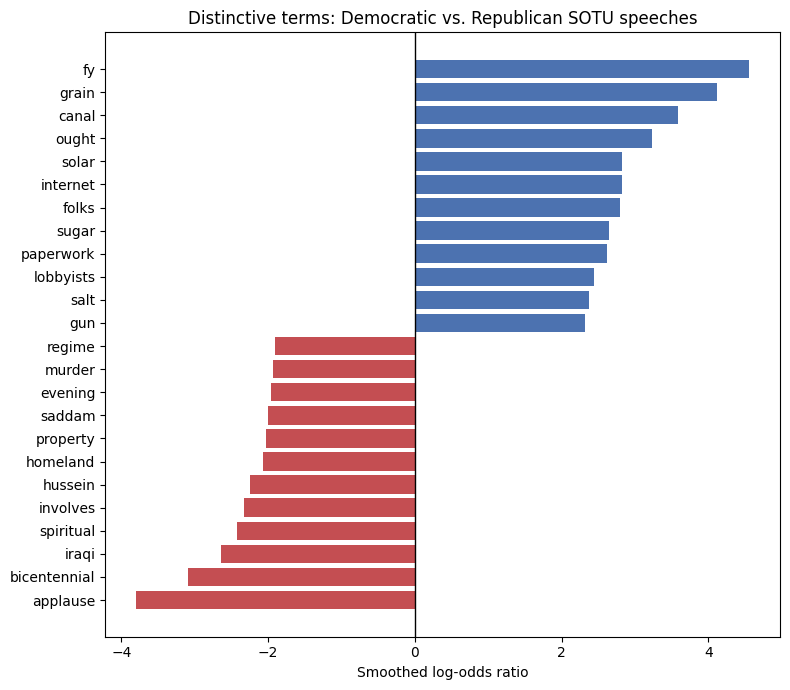

In [ ]:
# Plot the terms with the most positive and negative party contrasts.
# Choose the most positive and most negative terms, then combine them in one chart.
top_dem = distinctive.sort_values('dem_vs_rep_log_odds', ascending=False).head(12)
top_rep = distinctive.sort_values('dem_vs_rep_log_odds', ascending=True).head(12)
plot_terms = pd.concat([top_rep, top_dem]).sort_values('dem_vs_rep_log_odds')

plt.figure(figsize=(8, 7))
# Color encodes which party the term favors; zero is the no-difference reference.
colors = np.where(plot_terms['dem_vs_rep_log_odds'] > 0, '#4C72B0', '#C44E52')
plt.barh(plot_terms['term'], plot_terms['dem_vs_rep_log_odds'], color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Distinctive terms: Democratic vs. Republican SOTU speeches')
plt.xlabel('Smoothed log-odds ratio')
plt.tight_layout()


## 7b. Log-odds funnel plot

A funnel plot shows the log-odds contrast against term frequency. Rare terms can have extreme log-odds simply because they appear only a few times. Frequent terms need a stronger and more consistent group imbalance to move far away from zero.

The dashed curves are a rough 95% reference band under an equal-split approximation. Terms outside the band are not automatically substantively meaningful, but they are better candidates for interpretation than isolated rare words.

,term,dem_count,rep_count,total_count,dem_vs_rep_log_odds,z_score
1979,work,683,339,1022,0.480,7.225
36,administration,519,248,767,0.517,6.702
295,college,134,25,159,1.441,6.674
1688,soviet,259,96,355,0.768,6.442
214,businesses,138,34,172,1.168,6.140
1488,regulatory,103,16,119,1.615,6.091
1983,working,297,128,425,0.618,5.858
391,countries,207,76,283,0.776,5.805
1559,rights,268,112,380,0.649,5.776
1813,terror,16,64,80,-1.586,-5.750


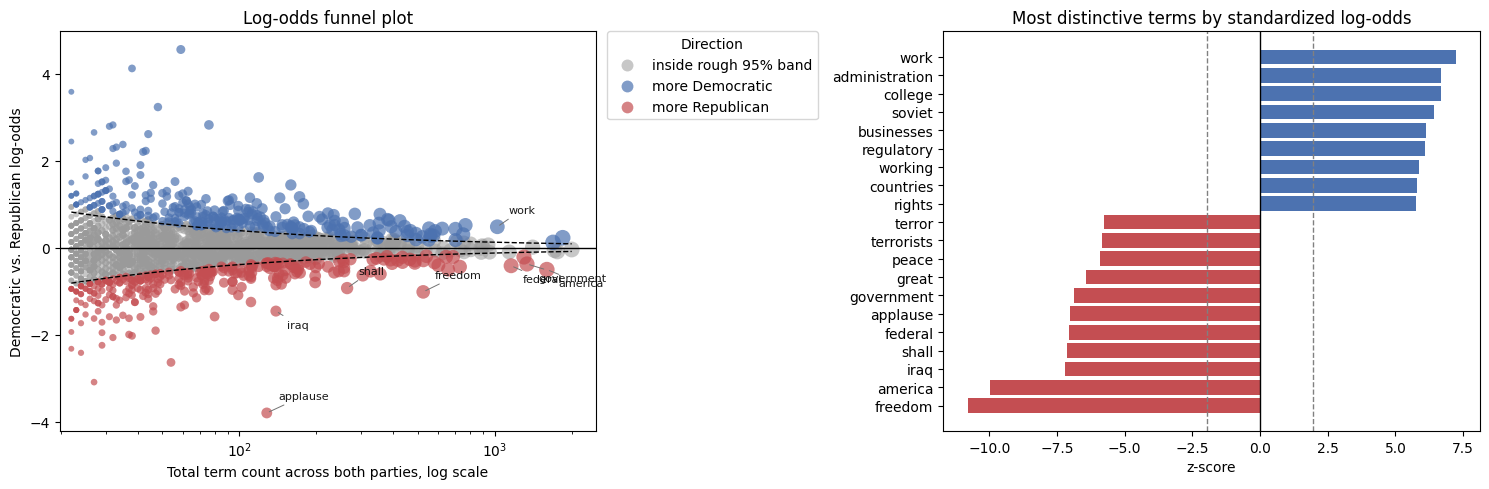

In [18]:
# Check whether extreme log odds are supported by enough occurrences to interpret.
# Use one row per term from the previous log-odds calculation.
funnel = distinctive.copy()
# Classify terms by whether their standardized contrast crosses about +/-1.96.
funnel['direction'] = 'inside rough 95% band'
funnel.loc[(funnel['z_score'] >= 1.96), 'direction'] = 'more Democratic'
funnel.loc[(funnel['z_score'] <= -1.96), 'direction'] = 'more Republican'

min_count = max(1, int(funnel['total_count'].min()))
max_count = max(10, int(funnel['total_count'].max()))
# Generate evenly spaced positions on a log scale for a smooth reference band.
funnel_counts = np.geomspace(min_count, max_count, 250)
# Reference band if a term's counts were split about evenly across the two groups.
# This rough band shrinks as total term count increases; it is a visual guide, not a formal test.
funnel_band = 1.96 * np.sqrt(4 / (funnel_counts + 2 * alpha))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

palette = {
    'more Democratic': '#4C72B0',
    'more Republican': '#C44E52',
    'inside rough 95% band': '#9A9A9A'
}

# Keep the point size visually useful, but avoid a separate size legend.
# Map log counts to marker size, keeping rare and common terms both visible.
point_sizes = np.interp(
    np.log1p(funnel['total_count']),
    (np.log1p(funnel['total_count']).min(), np.log1p(funnel['total_count']).max()),
    (18, 130)
)

for direction in ['inside rough 95% band', 'more Democratic', 'more Republican']:
    # Plot each category separately so the legend and colors explain the contrast.
    subset = funnel[funnel['direction'].eq(direction)]
    axes[0].scatter(
        subset['total_count'],
        subset['dem_vs_rep_log_odds'],
        s=point_sizes[subset.index],
        c=palette[direction],
        alpha=0.55 if direction == 'inside rough 95% band' else 0.7,
        linewidths=0,
        label=direction
    )

axes[0].plot(funnel_counts, funnel_band, color='black', linestyle='--', linewidth=1)
axes[0].plot(funnel_counts, -funnel_band, color='black', linestyle='--', linewidth=1)
axes[0].axhline(0, color='black', linewidth=1)
# Log count axis spreads out the many rare words on the left.
axes[0].set_xscale('log')
axes[0].set_xlim(min_count * 0.90, max_count * 1.25)
axes[0].set_title('Log-odds funnel plot')
axes[0].set_xlabel('Total term count across both parties, log scale')
axes[0].set_ylabel('Democratic vs. Republican log-odds')
axes[0].legend(title='Direction', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

# Label a small set of interpretable terms: outside the band and not extremely rare.
# Label only frequent enough terms outside the band; labeling every point would overlap.
label_candidates = funnel[
    funnel['direction'].ne('inside rough 95% band')
    & funnel['total_count'].ge(funnel['total_count'].quantile(0.55))
].copy()
# Within those candidates, keep the eight largest absolute standardized contrasts.
label_terms = label_candidates.reindex(
    label_candidates['z_score'].abs().sort_values(ascending=False).head(8).index
)

for label_i, (_, row) in enumerate(label_terms.iterrows()):
    y_offset = 0.18 if label_i % 2 == 0 else -0.18
    axes[0].annotate(
        row['term'],
        xy=(row['total_count'], row['dem_vs_rep_log_odds']),
        xytext=(8, 10 if y_offset > 0 else -12),
        textcoords='offset points',
        fontsize=8,
        alpha=0.9,
        arrowprops={'arrowstyle': '-', 'color': '0.45', 'lw': 0.7}
    )

# The right panel ranks terms by z-score, which accounts for count uncertainty.
top_z = funnel.reindex(funnel['z_score'].abs().sort_values(ascending=False).head(20).index).sort_values('z_score')
bar_colors = np.where(top_z['z_score'] > 0, '#4C72B0', '#C44E52')
axes[1].barh(top_z['term'], top_z['z_score'], color=bar_colors)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].axvline(1.96, color='gray', linestyle='--', linewidth=1)
axes[1].axvline(-1.96, color='gray', linestyle='--', linewidth=1)
axes[1].set_title('Most distinctive terms by standardized log-odds')
axes[1].set_xlabel('z-score')
axes[1].set_ylabel('')

plt.tight_layout()

display(
    top_z[['term', 'dem_count', 'rep_count', 'total_count', 'dem_vs_rep_log_odds', 'z_score']]
    .sort_values('z_score', ascending=False)
    .round(3)
)


## 8. Document similarity

A vector space lets us ask which speeches are similar. Similarity is a property of the representation, not just the original texts.

In [19]:
# Weight speeches with TF-IDF and compare every pair by cosine similarity.
# TF-IDF lowers the weight of terms common to many speeches; min_df and max_features limit the vocabulary.
tfidf_vec = TfidfVectorizer(analyzer=spacy_analyzer, min_df=2, max_features=3000)
tfidf = tfidf_vec.fit_transform(modern['text'])
# The square matrix gives every speech pair's cosine similarity, including self-pairs on the diagonal.
similarity = cosine_similarity(tfidf)

# Keep each unordered speech pair once; the similarity matrix is symmetric.
pairs = []
labels = modern['doc_label'].to_list()
parties = modern['party'].to_list()

# Use j > i so each pair appears once and no speech is paired with itself.
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        pairs.append({
            'doc_1': labels[i],
            'party_1': parties[i],
            'doc_2': labels[j],
            'party_2': parties[j],
            'cosine_similarity': similarity[i, j]
        })

pd.DataFrame(pairs).sort_values('cosine_similarity', ascending=False).head(10)


,doc_1,party_1,doc_2,party_2,cosine_similarity
2221,Jimmy Carter (1980),Democratic,Jimmy Carter (1981),Democratic,0.898681
2136,Jimmy Carter (1979),Democratic,Jimmy Carter (1980),Democratic,0.879629
2138,Jimmy Carter (1979),Democratic,Jimmy Carter (1981),Democratic,0.843956
2049,Jimmy Carter (1978),Democratic,Jimmy Carter (1980),Democratic,0.837789
2047,Jimmy Carter (1978),Democratic,Jimmy Carter (1979),Democratic,0.831990
2051,Jimmy Carter (1978),Democratic,Jimmy Carter (1981),Democratic,0.797590
1816,Richard M. Nixon (1974),Republican,Jimmy Carter (1981),Democratic,0.783776
1812,Richard M. Nixon (1974),Republican,Jimmy Carter (1979),Democratic,0.781629
1814,Richard M. Nixon (1974),Republican,Jimmy Carter (1980),Democratic,0.780388
1704,Richard M. Nixon (1972),Republican,Richard M. Nixon (1974),Republican,0.764201


In [20]:
tfidf_dtm = pd.DataFrame(tfidf.toarray(), columns=tfidf_vec.get_feature_names_out(), index=modern['X'])
# test
sim = pd.DataFrame(similarity)
sim

,0,1,2,3,4,5,6,7,8,9,...,69,70,71,72,73,74,75,76,77,78
0,1.000000,0.462593,0.527308,0.520372,0.486065,0.525783,0.580683,0.342473,0.579561,0.574094,...,0.341121,0.314739,0.355385,0.344915,0.348807,0.353824,0.353195,0.302782,0.156278,0.305817
1,0.462593,1.000000,0.632626,0.421154,0.619252,0.435866,0.442675,0.228204,0.425839,0.438358,...,0.274255,0.273800,0.302213,0.298212,0.310091,0.297376,0.300230,0.270654,0.121125,0.239843
2,0.527308,0.632626,1.000000,0.474487,0.578236,0.500410,0.513866,0.343614,0.529453,0.449373,...,0.371547,0.358141,0.372076,0.390522,0.384392,0.386831,0.370441,0.348360,0.157907,0.307171
3,0.520372,0.421154,0.474487,1.000000,0.427278,0.628555,0.624656,0.340044,0.636137,0.561715,...,0.310664,0.297416,0.320725,0.303886,0.282081,0.290964,0.329132,0.283103,0.137845,0.279781
4,0.486065,0.619252,0.578236,0.427278,1.000000,0.423633,0.454255,0.254367,0.458680,0.471411,...,0.322252,0.312023,0.313559,0.326926,0.343760,0.360033,0.328310,0.294463,0.146466,0.289990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,0.353824,0.297376,0.386831,0.290964,0.360033,0.295227,0.313314,0.230480,0.335154,0.299280,...,0.601482,0.598084,0.610632,0.645325,0.664751,1.000000,0.515520,0.519590,0.248862,0.466160
75,0.353195,0.300230,0.370441,0.329132,0.328310,0.335697,0.337866,0.225827,0.363472,0.335902,...,0.531831,0.533676,0.530407,0.538846,0.547069,0.515520,1.000000,0.666593,0.342784,0.606456
76,0.302782,0.270654,0.348360,0.283103,0.294463,0.290496,0.292277,0.191043,0.314274,0.258206,...,0.535321,0.534150,0.534515,0.542167,0.541699,0.519590,0.666593,1.000000,0.390061,0.645976
77,0.156278,0.121125,0.157907,0.137845,0.146466,0.134606,0.138072,0.094825,0.152341,0.140520,...,0.245724,0.246379,0.253723,0.254257,0.254005,0.248862,0.342784,0.390061,1.000000,0.389127


## 8a. Similarity heatmap

Similarity matrices are useful for checking whether documents cluster by time, speaker, party, genre, or some artifact of preprocessing.

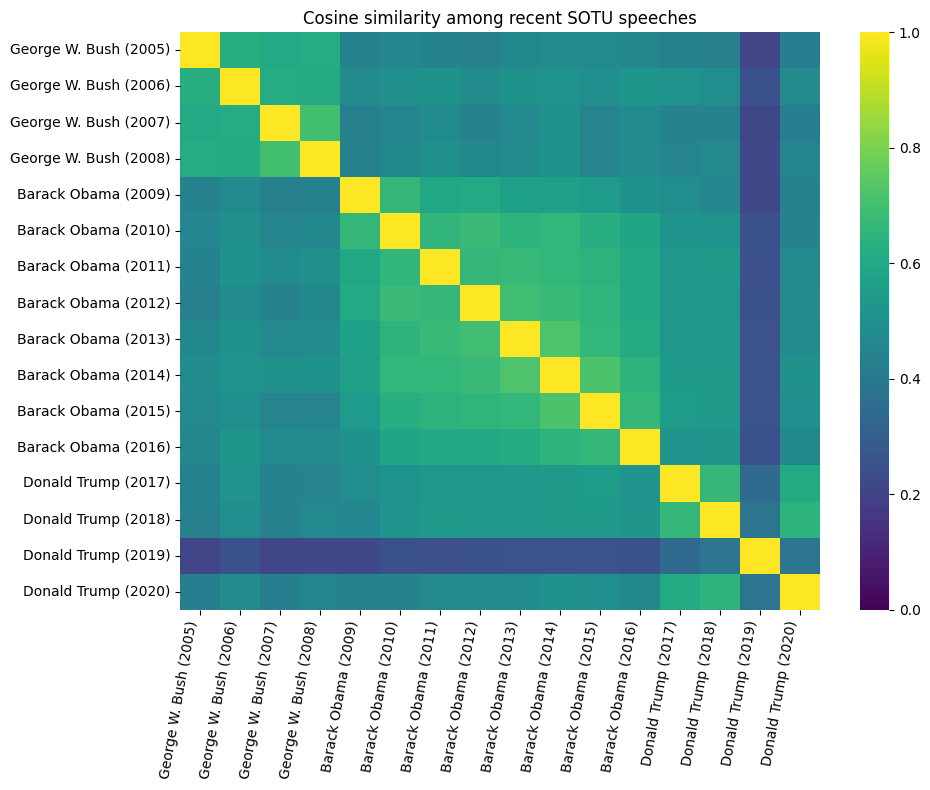

In [21]:
# Display similarities among recent speeches as a heatmap.
# Use the 16 latest speeches for a readable heatmap.
recent = modern.sort_values('year_numeric').tail(16).copy()
# transform reuses the earlier vocabulary and IDF weights; fitting again would change the measurement.
recent_tfidf = tfidf_vec.transform(recent['text'])
recent_similarity = cosine_similarity(recent_tfidf)

plt.figure(figsize=(10, 8))
# Each square compares two speeches; the diagonal is 1 because a speech matches itself.
sns.heatmap(
    recent_similarity,
    xticklabels=recent['doc_label'],
    yticklabels=recent['doc_label'],
    cmap='viridis',
    vmin=0,
    vmax=1
)
plt.title('Cosine similarity among recent SOTU speeches')
plt.xticks(rotation=80, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()


## 8b. Representation geometry: what SVD shows

The TF-IDF matrix has one row per speech and one column per retained term (up to 3,000 here). **Singular value decomposition (SVD)** compresses that large matrix into a smaller number of new axes. `TruncatedSVD(n_components=2)` keeps two axes so that we can draw each speech as a point. The picture is a diagnostic view: reducing thousands of dimensions to two loses information.

A **component** is a weighted combination of terms learned from patterns across the speeches. It is not one word, a predefined topic, or a party label. `svd2.components_[0]` contains the term weights for component 1, while `coords[:, 0]` gives each speech’s score on that component (the horizontal position). Index `1` gives the weights and scores for component 2 (the vertical position). Python starts counting at zero, which is why component 1 uses `[0]`.

To interpret a component, examine its largest positive and negative term weights using the vocabulary from `tfidf_vec`, then read speeches near either end of the axis. The sign can flip without changing which speeches are close together. A high term weight describes an axis; it is not a probability, a significance test, or evidence that a party caused a pattern.

The optional cells below fit five components and plot components 3 and 5. They print ten high-magnitude term weights for interpretation, but the speech coordinates come from the full fitted TF-IDF vocabulary, not only those ten terms. `svd.explained_variance_ratio_` reports the variance accounted for by each retained component.

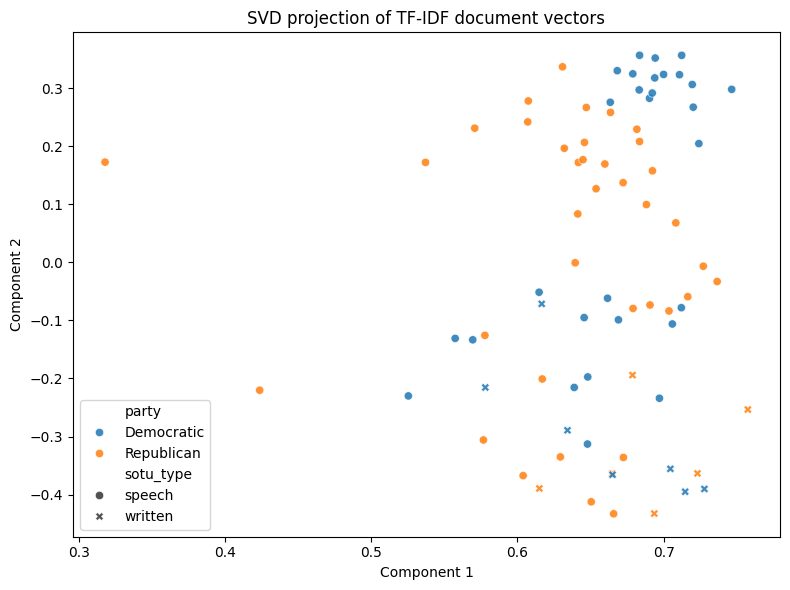

In [48]:
# Project the document vectors into two dimensions for a diagnostic view.
# Compress thousands of TF-IDF dimensions to two for a picture, losing information in the process.
svd2 = TruncatedSVD(n_components=2, random_state=42)
# Each speech now has two plotting coordinates; these axes are not named topics.
coords = svd2.fit_transform(tfidf)

# Attach metadata to the coordinates in the same row order as tfidf.
plot_df = modern[['president', 'year_numeric', 'party', 'sotu_type']].copy()
plot_df['x'] = coords[:, 0]
plot_df['y'] = coords[:, 1]

plt.figure(figsize=(8, 6))
# Color and shape reveal whether apparent clusters line up with party or speech type.
sns.scatterplot(data=plot_df, x='x', y='y', hue='party', style='sotu_type', alpha=0.85)
plt.title('SVD projection of TF-IDF document vectors')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.tight_layout()


## 9. Student task: change one representation

Run the cells above first. The code below fits a **baseline** using
word counts with min_df=2, then fits one **changed** representation
to the same speeches. Change only the task_choice value and rerun.

Choose one:

1. **min_df:** raise the minimum document frequency from 2 to 5.
   A term must occur in at least five different speeches to remain.
2. **binary:** count whether a term occurs in a speech (0 or 1)
   instead of how many times it occurs.
3. **bigrams:** keep unigrams and add adjacent word pairs.

Optional extension:
Compare the number of features, terms added or removed, top terms,
and speech pairs whose cosine similarity changes most. A change in
min_df may leave the top words almost untouched while removing many
rare features; inspect the vocabulary and similarity results too.

Write three sentences: **What changed? Why? Which representation
better fits the research question?** The before/after-1980 comparison
is a separate optional extension below because it changes the groups,
rather than the representation.
